# Notebook 05: Automated Paper Artifacts & Publication Visualizations

This notebook orchestrates publication artifact generation for the MCTS-HNM manuscript:
1. Loads paper metadata from `paper_metadata.yaml` (title, authors, PPGC UFRGS affiliation).
2. Reads multi-seed benchmark results (or deterministic synthetic distributions).
3. Renders and exports publication-grade vector PDF and raster PNG figures into `paper/figures/`.
4. Renders and exports LaTeX `booktabs` tables into `paper/tables/`.
5. Compiles `paper/main.pdf` via pdflatex.


In [1]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

# Ensure project root is in sys.path
root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from src.utils.experiment_config import (
    ExecutionMode,
    ExperimentConfig,
    find_repo_root,
    get_isolated_paths,
    print_execution_banner,
)
from src.utils.paper_artifacts import (
    load_paper_metadata,
    generate_all_paper_artifacts,
    compile_paper,
)

EXECUTION_MODE = ExecutionMode.REAL
if os.environ.get("EXECUTION_MODE"):
    EXECUTION_MODE = ExecutionMode(os.environ["EXECUTION_MODE"].lower())
elif "pytest" in sys.modules:
    EXECUTION_MODE = ExecutionMode.SMOKE

repo_root = find_repo_root()
config = ExperimentConfig(
    execution_mode=EXECUTION_MODE,
    seed=42,
    num_steps=100,
)
print_execution_banner(config, notebook_name="05_paper_artifacts")
paths = get_isolated_paths(config, repo_root=repo_root)


Project root: /home/mlima/workspace/mcts-hnm


## 1. Paper Metadata Configuration
Inspecting metadata from `paper_metadata.yaml`:

In [2]:
meta = load_paper_metadata(repo_root / "paper_metadata.yaml")
print("Title:", meta.get("title"))
print("Authors:")
for a in meta.get("authors", []):
    print("  -", a.get("name"), f"({a.get('affiliation')})", f"<{a.get('email')}>")
print("Institution:")
print(meta.get("institution"))


Paper metadata file paper_metadata.yaml not found. Using default PPGC UFRGS metadata.


Title: MCTS-HNM: Monte Carlo Tree Search for Hierarchical Hard Negative Mining in Class-Imbalanced Learning
Authors:
  -  (PPGC - Universidade Federal do Rio Grande do Sul (UFRGS)) <>
  - Co-Author Placeholder (PPGC - Universidade Federal do Rio Grande do Sul (UFRGS)) <coauthor@inf.ufrgs.br>
Institution:
Postgraduate Program in Computer Science (PPGC)
Universidade Federal do Rio Grande do Sul (UFRGS)
Porto Alegre, RS, Brazil


## 2. Generate Publication Figures and Tables
Generating all figures (PDF & PNG) and tables (LaTeX booktabs):

In [3]:
artifacts = generate_all_paper_artifacts(
    results_dir=paths.results_dir,
    paper_dir=repo_root / "paper" if EXECUTION_MODE == ExecutionMode.REAL else paths.paper_figures_dir.parent,
    metadata_path=repo_root / "paper_metadata.yaml",
    config=config,
)

print("Generated figures:")
for fig in artifacts["figures"]:
    print(f"  - {fig}")

print("")
print("Generated tables:")
for tab in artifacts["tables"]:
    print(f"  - {tab}")

print("")
print(f"Artifact Manifest: {artifacts.get('manifest')}")


Paper metadata file paper_metadata.yaml not found. Using default PPGC UFRGS metadata.


Generated figures:
  - paper/figures/fig_convergence_curves.pdf
  - paper/figures/fig_convergence_curves.png
  - paper/figures/fig_tree_visitation_heatmap.pdf
  - paper/figures/fig_tree_visitation_heatmap.png
  - paper/figures/fig_hyperparameter_sensitivity.pdf
  - paper/figures/fig_hyperparameter_sensitivity.png

Generated tables:
  - paper/tables/tab_scenario1_imbalanced.tex
  - paper/tables/tab_scenario2_multiclass.tex
  - paper/tables/tab_ablation_study.tex


## 3. Interactive Visualization of Publication Figures

### Figure 1: Convergence Curves

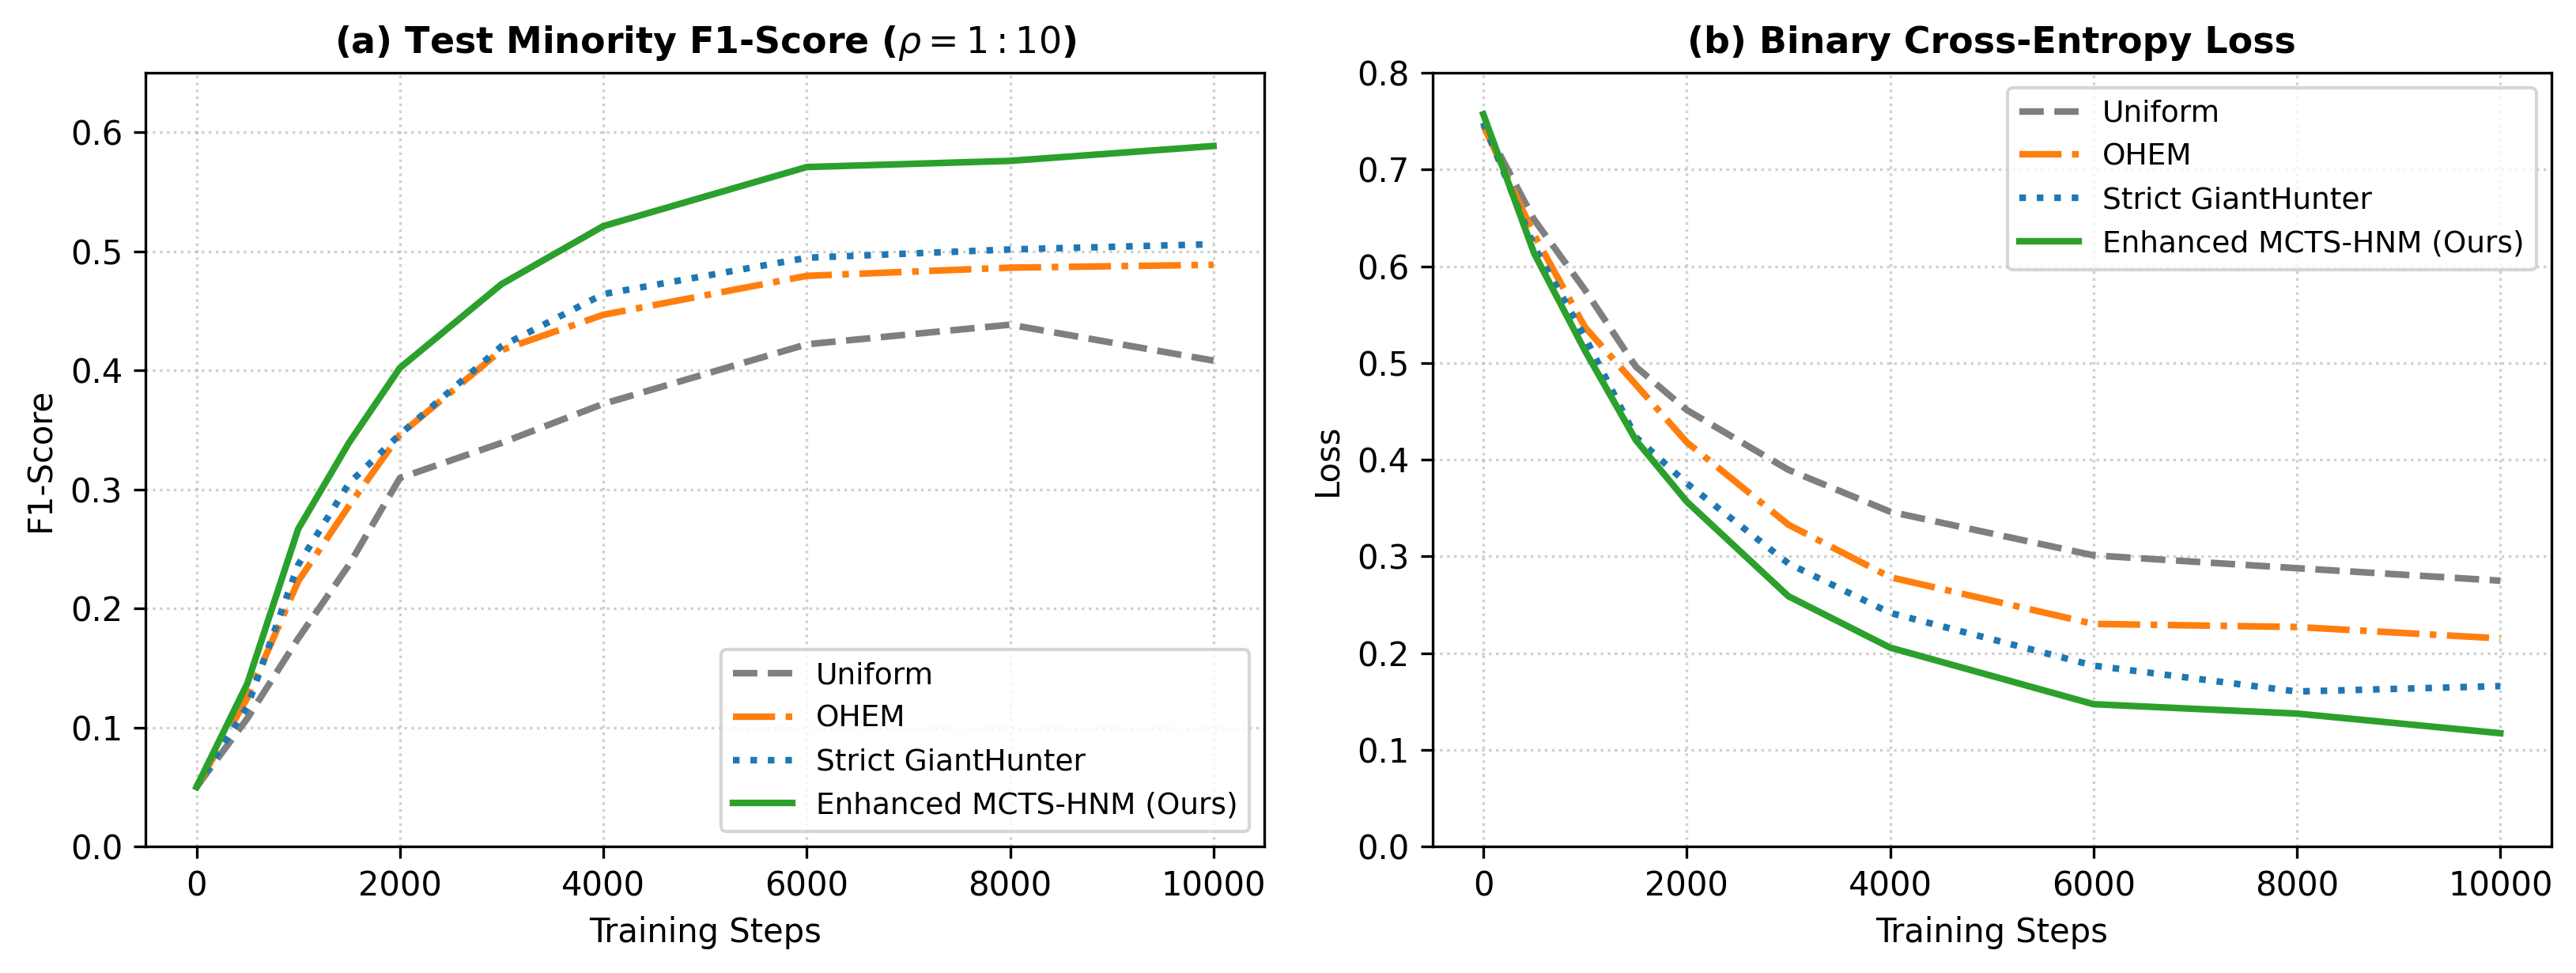

### Figure 2: Tree Visitation Heatmap

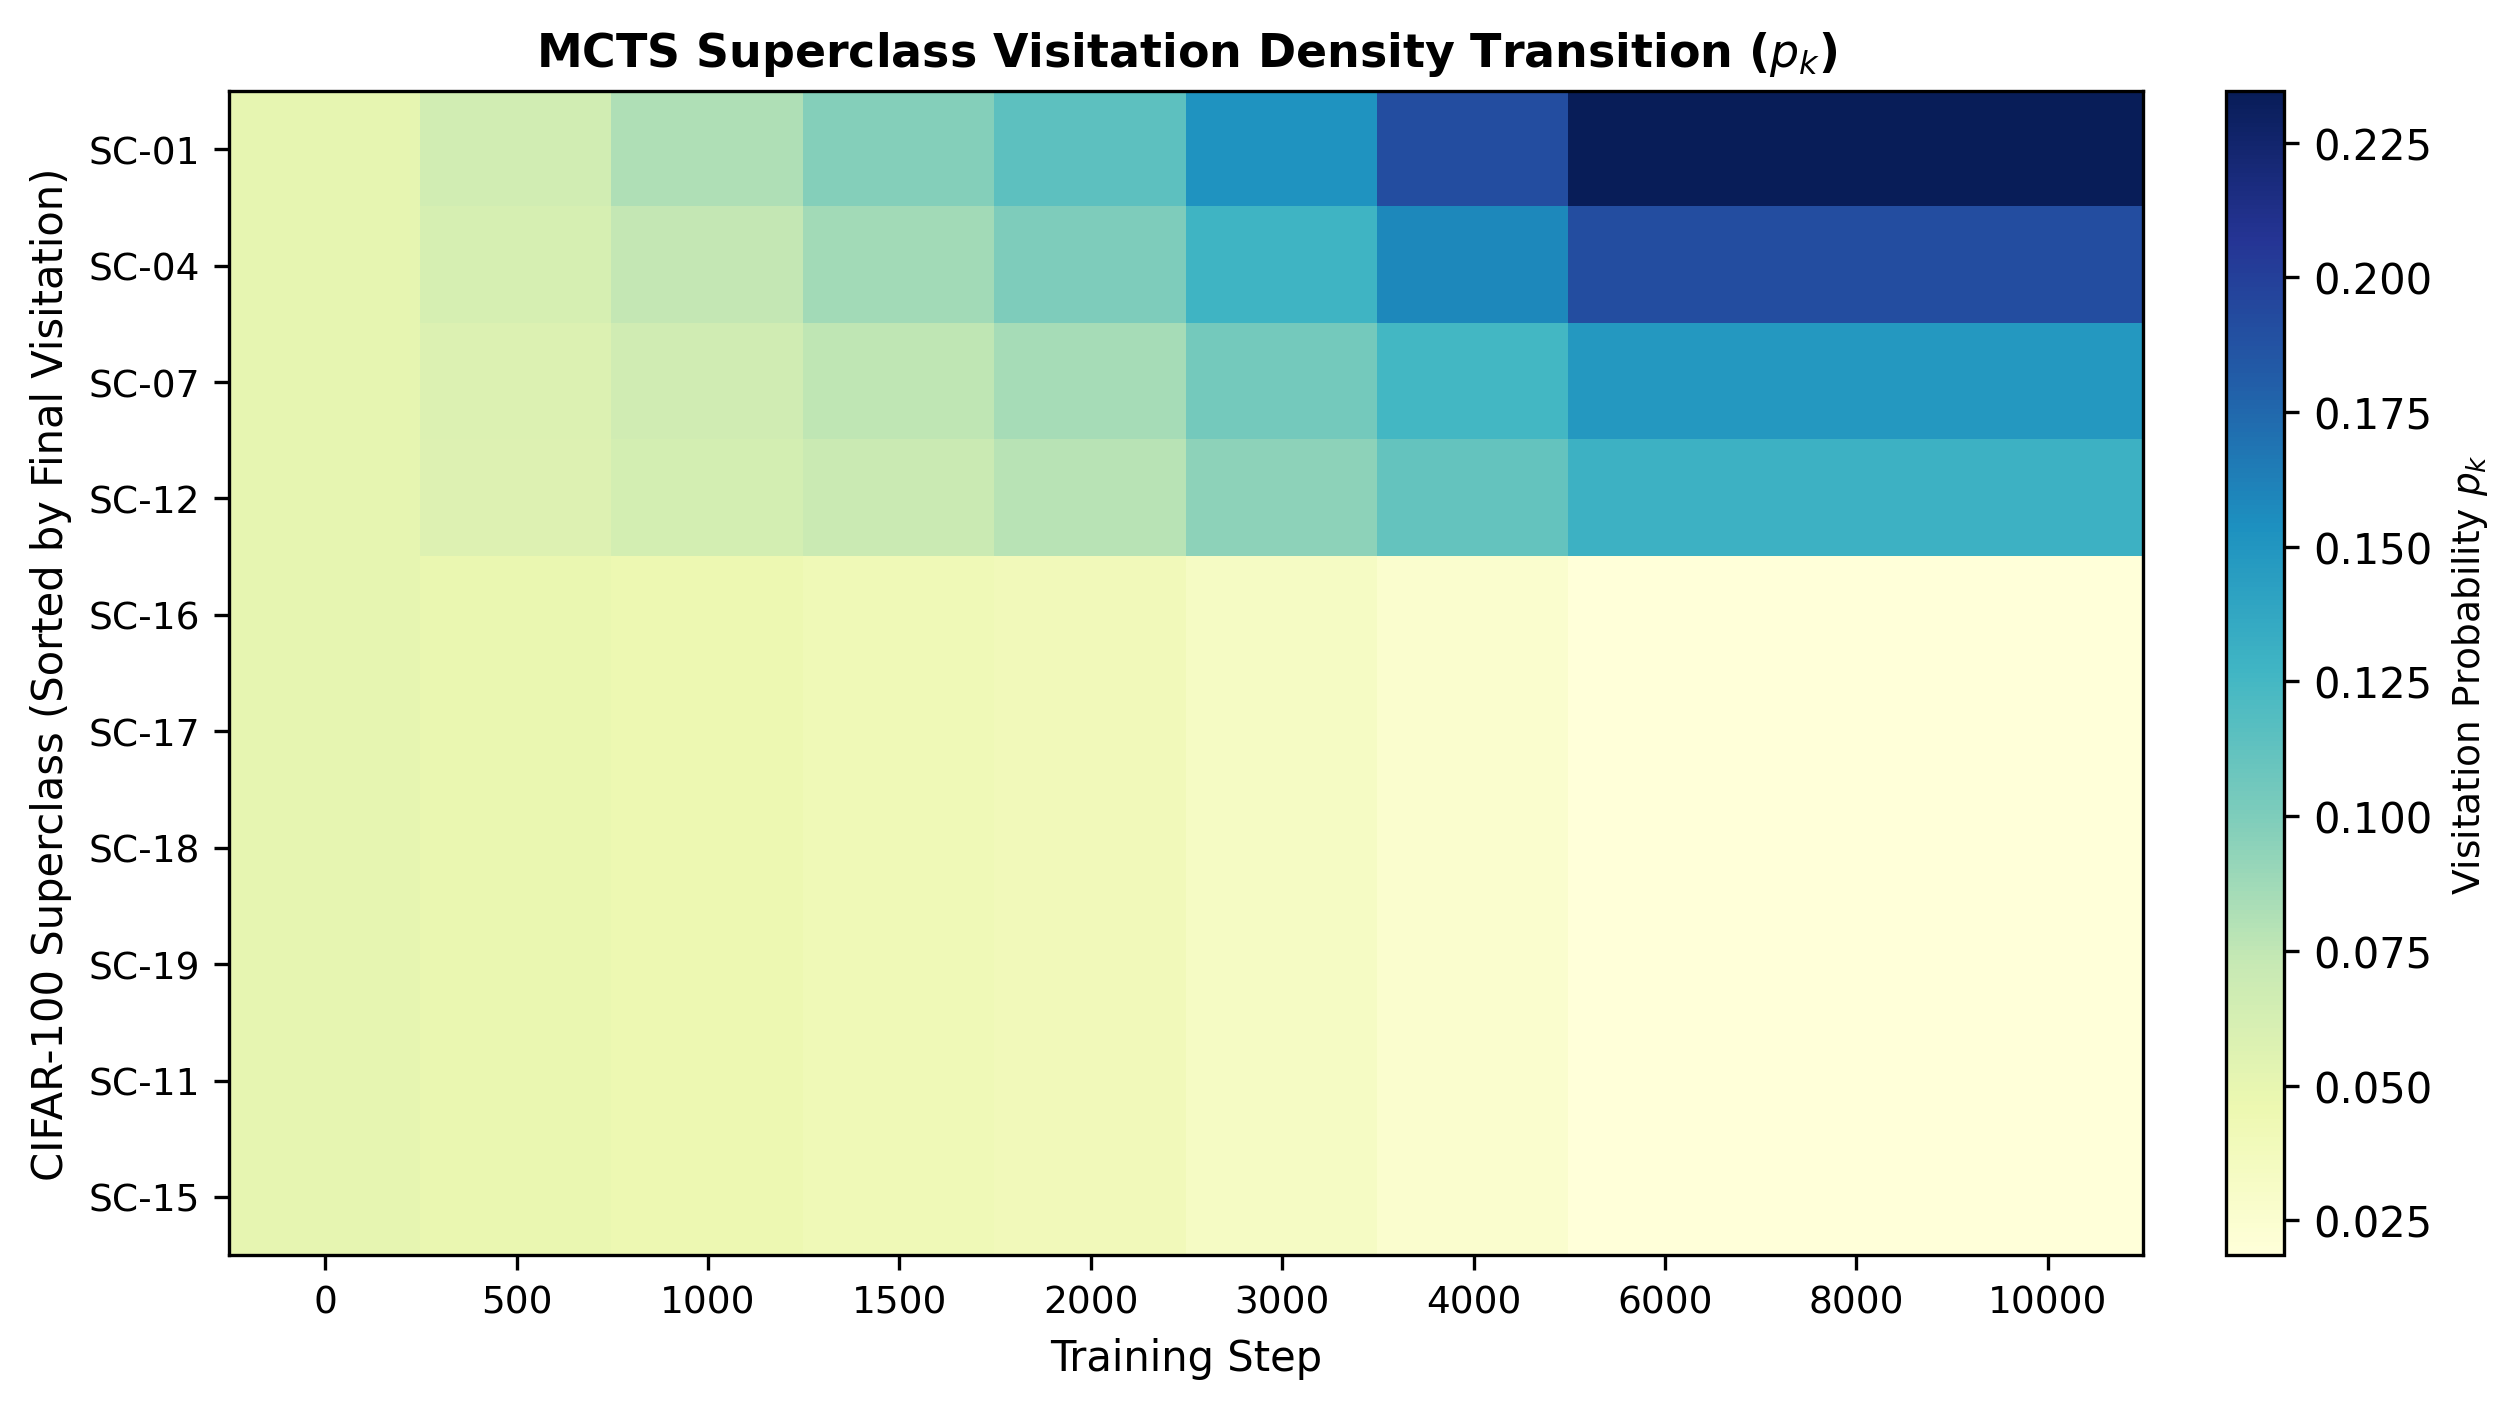

### Figure 3: Hyperparameter Sensitivity

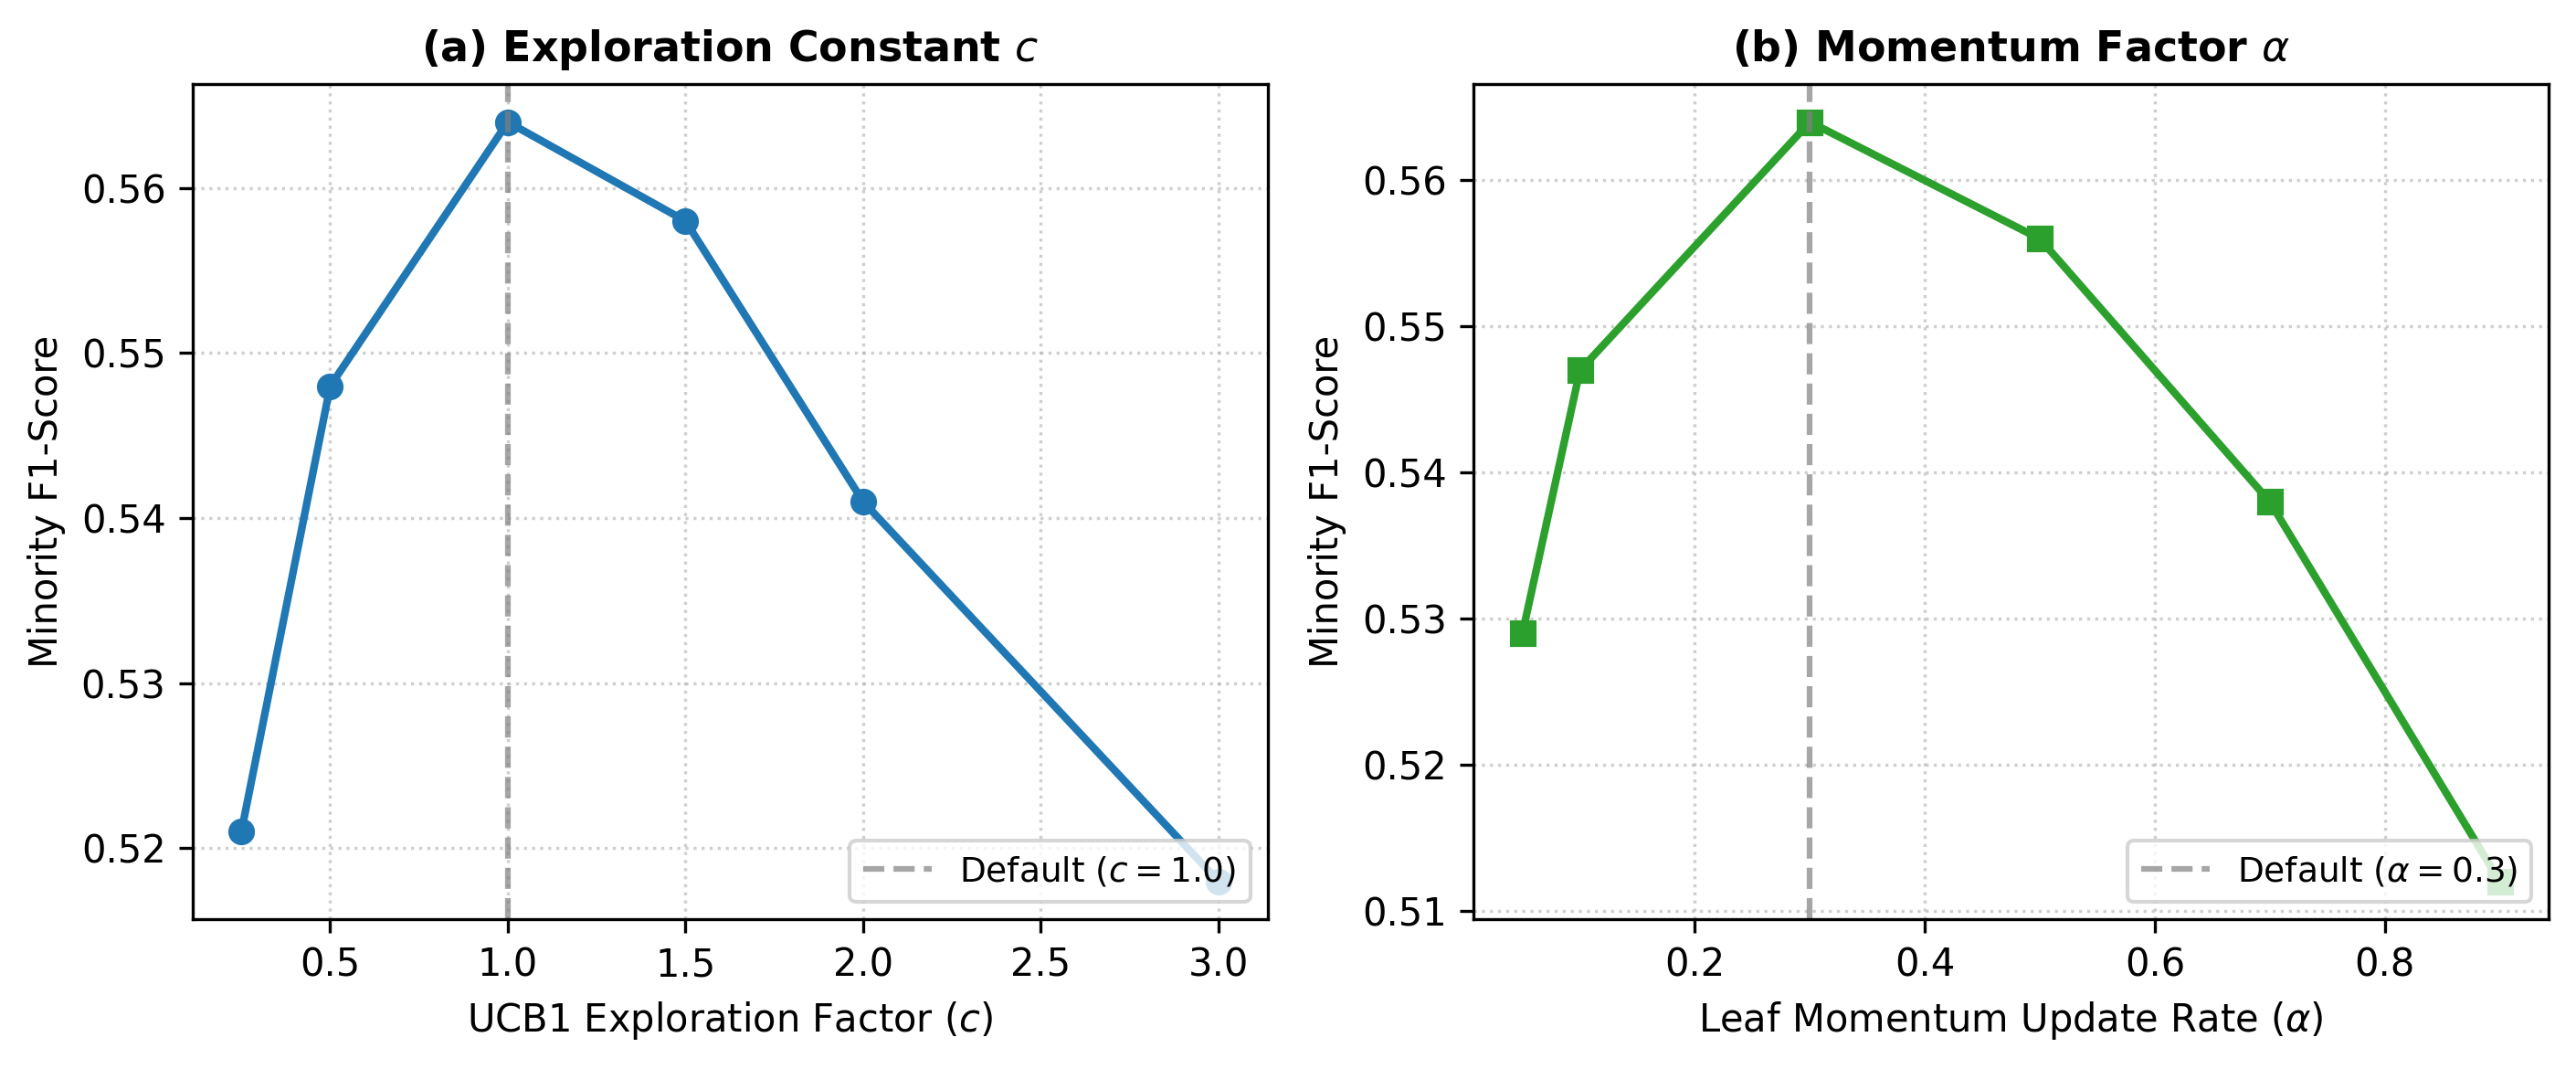

In [4]:
fig_dir = paths.paper_figures_dir
display(Markdown("### Figure 1: Convergence Curves"))
display(Image(filename=str(fig_dir / "fig_convergence_curves.png")))

display(Markdown("### Figure 2: Tree Visitation Heatmap"))
display(Image(filename=str(fig_dir / "fig_tree_visitation_heatmap.png")))

display(Markdown("### Figure 3: Hyperparameter Sensitivity"))
display(Image(filename=str(fig_dir / "fig_hyperparameter_sensitivity.png")))


## 4. Compile LaTeX Manuscript
Compiling `paper/main.tex` to `paper/main.pdf`:

In [5]:
try:
    target_paper_dir = repo_root / "paper"
    pdf_path = compile_paper(target_paper_dir)
    print(f"Successfully compiled: {pdf_path} ({pdf_path.stat().st_size:,} bytes)")
except Exception as e:
    print(f"Compilation notice: {e}")


Compilation notice: LaTeX document not found at /home/mlima/workspace/mcts-hnm/notebooks/paper/main.tex
